In [1]:
#Example code from LightFM

from lightfm import LightFM
from lightfm.datasets import fetch_movielens
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
import numpy as np
import matplotlib.pyplot as plt

# Load the MovieLens 100k dataset. Only five
# star ratings are treated as positive.
data = fetch_movielens(min_rating=5.0)

# Instantiate and train the model
model = LightFM(loss='warp')
model.fit(data['train'], epochs=30, num_threads=2)

# Evaluate the trained model
test_precision = precision_at_k(model, data['test'], k=10).mean()
print(test_precision)
test_recall = recall_at_k(model, data['test'], k=10).mean()
print(test_recall)

train_precision = precision_at_k(model, data['train'], k=10).mean()
print(train_precision)
train_recall = recall_at_k(model, data['train'], k=10).mean()
print(train_recall)

0.044121534
0.17240936445031557
0.34994525
0.3192233747549635


In [2]:
# measure precision/recall @ k for k=1:50
test_precision = []
test_recall = []
train_precision = []
train_recall = []

for i in np.arange(1, 51):
    test_precision.append(precision_at_k(model, data['test'], k=i).mean())
    test_recall.append(recall_at_k(model, data['test'], k=i).mean())
    train_precision.append(precision_at_k(model, data['train'], k=i).mean())
    train_recall.append(recall_at_k(model, data['train'], k=i).mean())

Text(0.5, 1.0, 'Precision-Recall Curves for Example Code MovieLens LightFM model')

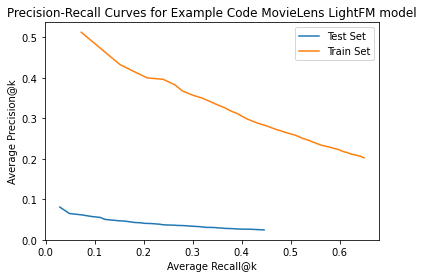

In [4]:
#Plot precision-recall curves for train and test data
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(test_recall, test_precision)
plt.plot(train_recall, train_precision)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for Example Code MovieLens LightFM model')